# Quickstart: recover a hidden descriptor

iBART looks for a *descriptor*: a short formula built from your input features
that explains a response. It does that by alternating two steps:

1. **Grow**: apply operators (`x^2`, `sqrt`, `log`, `a*b`, `a/b`, `|a-b|`, ...) to
   every descriptor in the pool, so the pool explodes combinatorially.
2. **Prune**: screen the pool with a variable-selection method (BART, or a
   differentiable gate model) and keep only the descriptors that matter.

After the last round, LASSO and an exhaustive l0 best-subset search pick the
final few descriptors, and an ordinary least-squares fit gives their
coefficients. The result is a small, symbolic, linear-in-the-coefficients model
that you can read.

In this notebook we hide a product `a*b` among six features and let iBART find it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jax_ibart import IBart

rng = np.random.default_rng(0)
n = 90
names = ["a", "b", "c", "d", "e", "f"]
X = rng.uniform(0.5, 2.0, size=(n, len(names)))
a, b = X[:, 0], X[:, 1]
# the response depends only on the product a*b; c..f are distractors
y = 5.0 * a * b + rng.normal(0, 0.05, n)
X.shape

(90, 6)

## Look at the data first

Plotted against any single feature, `y` is a cloud. `a` and `b` each show a
trend, but neither explains `y` on its own, and `c`..`f` show nothing.

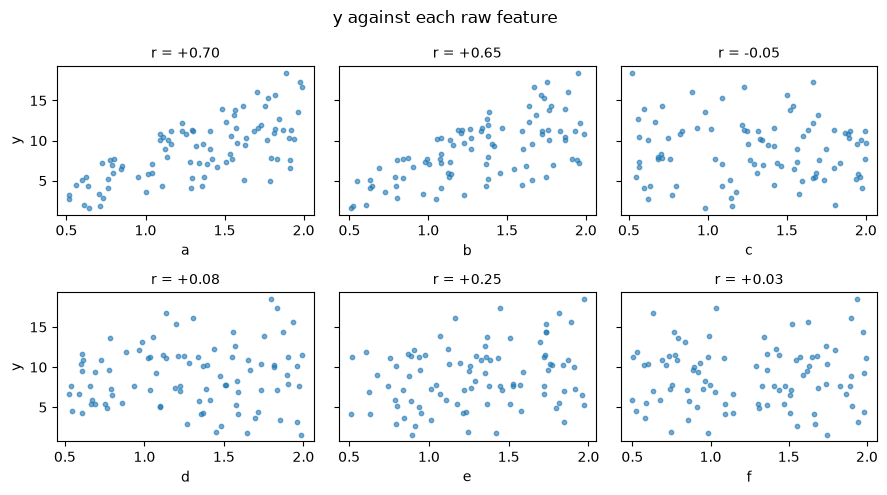

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(9, 5), sharey=True)
for j, ax in enumerate(axes.flat):
    r = np.corrcoef(X[:, j], y)[0, 1]
    ax.scatter(X[:, j], y, s=10, alpha=0.6)
    ax.set_xlabel(names[j])
    ax.set_title(f"r = {r:+.2f}", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("y")
fig.suptitle("y against each raw feature")
fig.tight_layout()
plt.show()

## Fit

One binary round (`schedule=("b",)`) is enough to build `a*b`. We ask for a
single descriptor (`max_dim=1`) and use the differentiable `diff` backend, which
runs in seconds and needs nothing beyond JAX. (`backend="bart"` is the faithful
BART-G.SE screen; see the [backends notebook](03_backends.ipynb).)

In [3]:
model = IBart(backend="diff", schedule=("b",), max_dim=1, seed=0, steps=1200)
model.fit(X, y, feature_names=names)
model.descriptors_

[a*b]

## What happened inside: grow, then prune

`model.history_` records the pool size at each stage. The binary round turned 6
features into 90 candidate descriptors (pairwise sums, differences, products,
quotients and absolute differences, after removing duplicates). The screen kept
a handful, and the l0 search chose one.

In [4]:
def plot_history(history, ax=None, title="Descriptor pool at each stage"):
    """Bar chart of pool size generated vs kept at each pipeline stage."""
    import matplotlib.pyplot as plt
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.2))
    labels = {"primary": "primary\nfeatures", "u": "unary\nops", "b": "binary\nops",
              "l0": "LASSO + l0"}
    xs = np.arange(len(history))
    gen = [h["generated"] for h in history]
    kept = [h["kept"] for h in history]
    ax.bar(xs - 0.2, gen, 0.4, label="generated", color="C0")
    ax.bar(xs + 0.2, kept, 0.4, label="kept after screening", color="C1")
    for x, g, k in zip(xs, gen, kept):
        ax.text(x - 0.2, g, f"{g:,}", ha="center", va="bottom", fontsize=8)
        ax.text(x + 0.2, k, f"{k:,}", ha="center", va="bottom", fontsize=8)
    ax.set_yscale("log")
    ax.set_xticks(xs, [labels.get(h["stage"], h["stage"]) for h in history])
    ax.set_ylabel("number of descriptors")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
    return ax

{'stage': 'primary', 'generated': 6, 'kept': 6}
{'stage': 'b', 'generated': 90, 'kept': 2}
{'stage': 'l0', 'generated': 2, 'kept': 1}


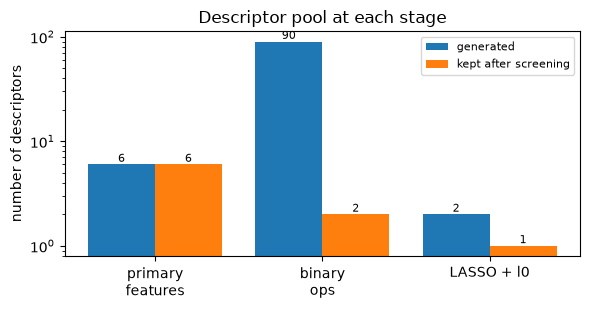

In [5]:
for h in model.history_:
    print(h)
plot_history(model.history_)
plt.tight_layout()
plt.show()

## The descriptor collapses the data

Plotted against the discovered descriptor, the cloud collapses onto a line: that
is what it means for `a*b` to be the right variable. The parity plot shows the
fitted model against the data.

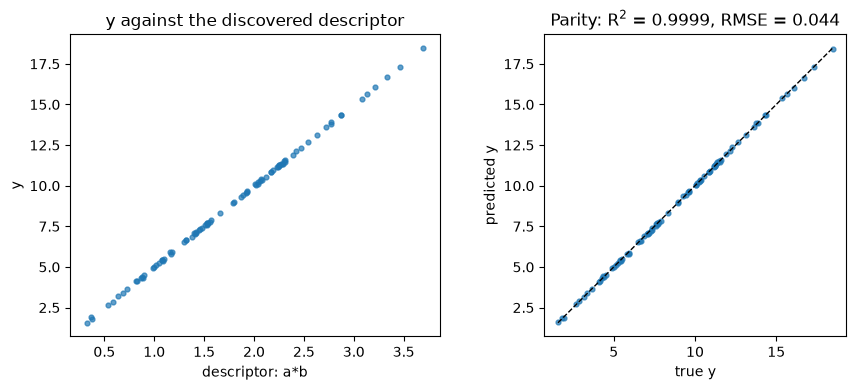

In [6]:
pred = model.predict(X)
resid = y - pred
r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
rmse = np.sqrt((resid ** 2).mean())
D = model.transform(X)[:, 0]   # the descriptor evaluated on the data

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].scatter(D, y, s=12, alpha=0.7)
axes[0].set_xlabel(f"descriptor: {model.descriptors_[0]}")
axes[0].set_ylabel("y")
axes[0].set_title("y against the discovered descriptor")

lo, hi = float(min(y.min(), pred.min())), float(max(y.max(), pred.max()))
axes[1].plot([lo, hi], [lo, hi], "k--", lw=1)
axes[1].scatter(y, pred, s=12, alpha=0.7)
axes[1].set_xlabel("true y")
axes[1].set_ylabel("predicted y")
axes[1].set_title(f"Parity: R$^2$ = {r2:.4f}, RMSE = {rmse:.3f}")
axes[1].set_aspect("equal")
fig.tight_layout()
plt.show()

## Read the model

The fitted model renders as LaTeX in a notebook, and can be exported as LaTeX or
HTML strings for papers and web pages. The coefficient comes out close to the
hidden 5.

In [7]:
model   # rich LaTeX rendering (via _repr_latex_)

In [8]:
print("expression:", model.expression())
print("latex     :", model.latex())

expression: 4.99*a*b + 0.01599
latex     : y = 4.99 a b + 0.01599


## Where next

- [Catalysis case study](02_catalysis.ipynb): the real problem iBART was built
  for: 91 data points, 59 features, and a published answer to compare against.
- [Backends](03_backends.ipynb): what the `bart` and `diff` screens actually
  compute, and when to use which.
- [Custom operators and units](04_custom_operators_units.ipynb): add your own
  operators and use dimensional analysis to prune the search.
- [What iBART can and cannot find](07_nonlinear.ipynb) and
  [Uncertainty](08_uncertainty.ipynb).